# Capítulo 4 — Ensayos y Resultados (Notebook de análisis)

Esta notebook está diseñada para **extraer conclusiones y tablas/gráficos** para la redacción, sin generar CSVs nuevos.

## Estructura
- **4.1 Configuración experimental**
- **4.2 Resultados de los modelos predictivos (LSTM + GJR-GARCH)**
- **4.3 Impacto en la optimización de portafolios**
- **4.4 Discusión de resultados (plantilla guiada)**


In [86]:
from pathlib import Path
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)
sns.set_style('whitegrid')


In [87]:
# --- Parámetros principales del análisis ---
import os

def _find_repo_root() -> Path:
    """Detecta automáticamente la raíz del repo Markowitz en distintos entornos (Linux/Windows/Colab)."""
    candidates = []

    # 1) Variable opcional de entorno
    env_root = os.getenv('MARKOWITZ_ROOT')
    if env_root:
        candidates.append(Path(env_root))

    # 2) Directorio de trabajo y sus padres
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])

    # 3) Rutas comunes en distintos setups
    candidates.extend([
        Path('/workspace/Markowitz'),
        Path('/content/Markowitz'),
        Path.home() / 'Markowitz',
    ])

    for cand in candidates:
        if (cand / 'Data' / 'returns.csv').exists() and (cand / 'outputs').exists():
            return cand

    raise FileNotFoundError(
        'No se encontró la raíz del repo. Definí MARKOWITZ_ROOT con la carpeta que contiene Data/ y outputs/.'
    )

ROOT = _find_repo_root()
print(f'ROOT detectado: {ROOT}')

# Corrida LSTM definitiva indicada por vos
LSTM_FINAL_RUN_ID = '20260419_214940'
LSTM_DIR = ROOT / 'outputs' / 'lstm_lab' / 'runs'

# Umbral de uso de predicción en el optimizador ai_returns_lstm
LSTM_DIR_ACC_THRESHOLD = 0.52

# Corridas de optimización a comparar (misma ponderación objetivo)
OPTIMIZATION_RUNS = {
    'Classic': {'run_id': 24, 'mlflow_run_id': '461fc6029f5d41639f0b20271c769903'},
    'LSTM': {'run_id': 25, 'mlflow_run_id': '6f3ec79561ea4be9a9995ca294e4ff6b'},
    'GRJ GARCH': {'run_id': 26, 'mlflow_run_id': '9a20f4ded8034debb61fadaabcc4ff51'},
}

TARGET_BLOCKS = {
    'AR': 0.20,
    'US': 0.50,
    'FUNDS_EQUITY': 0.12,
    'FUNDS_BONDS': 0.10,
    'GOLD': 0.08,
}

DB_PATH = ROOT / 'storage' / 'markowitz_app.db'


ROOT detectado: C:\Users\lucas\OneDrive\Documentos\GitHub\Markowitz


## 4.1 Configuración experimental

### Diagrama del pipeline experimental (texto)

```text
Data/returns.csv + metadata.csv
        │
        ├── Modelos IA
        │   ├── LSTM retornos -> outputs/lstm_lab/runs/<run_id>/...
        │   └── GJR-GARCH volatilidad -> outputs/predictions/volatility_predictions.csv
        │
        ├── Constructor de inputs de optimización
        │   ├── Classic: mu/cov históricos
        │   ├── ai_returns_lstm: mu LSTM (si dir_acc_test > 0.52) + fallback histórico
        │   └── ai_volatility: mu histórico + sigma con vol GJR-GARCH
        │
        └── Optimización Markowitz por bloques
            └── métricas, pesos, frontera, exposición
```


In [88]:
# Dataset base y tabla de activos
returns = pd.read_csv(ROOT / 'Data' / 'returns.csv', parse_dates=['Date'])

metadata_path_candidates = [
    ROOT / 'Data' / 'assets_metadata.csv',
    ROOT / 'Data' / 'asset_metadata.csv',  # compatibilidad por si cambia el nombre
]
metadata_path = next((p for p in metadata_path_candidates if p.exists()), None)
if metadata_path is None:
    raise FileNotFoundError('No se encontró assets_metadata.csv (ni asset_metadata.csv) dentro de Data/.')

metadata = pd.read_csv(metadata_path)
assets_table = metadata[['ticker', 'asset_class', 'block']].sort_values(['block', 'ticker']).reset_index(drop=True)

dataset_summary = pd.DataFrame([{
    'repo_root': str(ROOT),
    'archivo_metadata': metadata_path.name,
    'fecha_inicio': returns['Date'].min().date().isoformat(),
    'fecha_fin': returns['Date'].max().date().isoformat(),
    'n_filas_retornos': int(len(returns)),
    'n_activos': int(metadata['ticker'].nunique()),
    'n_bloques': int(metadata['block'].nunique()),
}])

print('Resumen del dataset:')
display(dataset_summary)
print('\nTabla de activos (base para tesis):')
display(assets_table)


Resumen del dataset:


,repo_root,archivo_metadata,fecha_inicio,fecha_fin,n_filas_retornos,n_activos,n_bloques
0,C:\Users\lucas\OneDrive\Documentos\GitHub\Mark...,assets_metadata.csv,2018-01-03,2025-12-31,2061,40,5



Tabla de activos (base para tesis):


,ticker,asset_class,block
0,ALUA.BA,Argentina Equity,AR
1,BBAR.BA,Argentina Equity,AR
2,BMA.BA,Argentina Equity,AR
3,CEPU.BA,Argentina Equity,AR
4,COME.BA,Argentina Equity,AR
5,EDN.BA,Argentina Equity,AR
6,GGAL.BA,Argentina Equity,AR
7,LOMA.BA,Argentina Equity,AR
8,PAMP.BA,Argentina Equity,AR
9,SUPV.BA,Argentina Equity,AR


In [89]:
# División train/val/test de la corrida LSTM definitiva
final_metrics = pd.read_csv(LSTM_DIR / LSTM_FINAL_RUN_ID / 'metrics.csv')

split_summary = pd.DataFrame([{
    'run_id': LSTM_FINAL_RUN_ID,
    'n_tickers': int(len(final_metrics)),
    'n_train_promedio': float(final_metrics['n_train'].mean()),
    'n_val_promedio': float(final_metrics['n_val'].mean()),
    'n_test_promedio': float(final_metrics['n_test'].mean()),
    'n_train_min': int(final_metrics['n_train'].min()),
    'n_train_max': int(final_metrics['n_train'].max()),
    'n_val_min': int(final_metrics['n_val'].min()),
    'n_val_max': int(final_metrics['n_val'].max()),
    'n_test_min': int(final_metrics['n_test'].min()),
    'n_test_max': int(final_metrics['n_test'].max()),
}])

display(split_summary)


KeyError: 'n_test'

## 4.2 Resultados de los modelos predictivos

In [ ]:
# Historial de corridas LSTM desde outputs/lstm_lab/runs/*
rows = []
for run_path in sorted(LSTM_DIR.glob('*')):
    summary_path = run_path / 'summary.json'
    metrics_path = run_path / 'metrics.csv'
    if not summary_path.exists() or not metrics_path.exists():
        continue
    summary = json.loads(summary_path.read_text())
    metrics = pd.read_csv(metrics_path)
    rows.append({
        'run_id': summary.get('run_id', run_path.name),
        'forecast_horizon': summary.get('forecast_horizon'),
        'target_aggregation': summary.get('target_aggregation'),
        'seq_len': summary.get('seq_len'),
        'epochs': summary.get('epochs'),
        'batch_size': summary.get('batch_size'),
        'lr': summary.get('lr'),
        'hidden_size': summary.get('hidden_size'),
        'num_layers': summary.get('num_layers'),
        'dropout': summary.get('dropout'),
        'tickers_with_predictions': summary.get('tickers_with_predictions', len(metrics)),
        'mean_rmse_test': float(metrics['rmse_test'].mean()),
        'mean_dir_acc_test': float(metrics['dir_acc_test'].mean()),
        'share_dir_acc_gt_052': float((metrics['dir_acc_test'] > LSTM_DIR_ACC_THRESHOLD).mean()),
    })

lstm_history = pd.DataFrame(rows).sort_values('run_id', ascending=False).reset_index(drop=True)

print('Historial LSTM (ordenado por run_id desc):')
display(lstm_history)

print('Top corridas por dir_acc_test (desempate: menor rmse_test):')
display(lstm_history.sort_values(['mean_dir_acc_test', 'mean_rmse_test'], ascending=[False, True]).head(10))


In [ ]:
# Parámetros y resultados de la corrida definitiva
final_summary = json.loads((LSTM_DIR / LSTM_FINAL_RUN_ID / 'summary.json').read_text())

final_params = pd.DataFrame([{
    'run_id': final_summary['run_id'],
    'start_date': final_summary.get('start_date'),
    'forecast_horizon': final_summary.get('forecast_horizon'),
    'target_aggregation': final_summary.get('target_aggregation'),
    'seq_len': final_summary.get('seq_len'),
    'epochs': final_summary.get('epochs'),
    'batch_size': final_summary.get('batch_size'),
    'lr': final_summary.get('lr'),
    'hidden_size': final_summary.get('hidden_size'),
    'num_layers': final_summary.get('num_layers'),
    'dropout': final_summary.get('dropout'),
    'selected_features': ', '.join(final_summary.get('selected_features', [])),
    'tickers_with_predictions': final_summary.get('tickers_with_predictions'),
    'mean_rmse_test_summary': final_summary.get('mean_rmse_test'),
    'mean_dir_acc_test_summary': final_summary.get('mean_dir_acc_test'),
}])

display(final_params)


In [ ]:
# Activos que pasan y que no pasan el umbral 0.52 (uso de mu_pred vs fallback histórico)
final_eval = final_metrics[['ticker', 'mu_pred', 'rmse_test', 'dir_acc_test', 'corr_test']].copy()
final_eval['use_lstm_mu_pred'] = final_eval['dir_acc_test'] > LSTM_DIR_ACC_THRESHOLD

passed = final_eval[final_eval['use_lstm_mu_pred']].sort_values('dir_acc_test', ascending=False)
failed = final_eval[~final_eval['use_lstm_mu_pred']].sort_values('dir_acc_test', ascending=True)

summary_threshold = pd.DataFrame([{
    'run_id': LSTM_FINAL_RUN_ID,
    'threshold_dir_acc_test': LSTM_DIR_ACC_THRESHOLD,
    'total_activos': len(final_eval),
    'activos_que_pasan': int(len(passed)),
    'activos_con_fallback_historico': int(len(failed)),
    'porcentaje_que_pasan': float(len(passed) / len(final_eval)),
}])

print('Resumen umbral LSTM para optimización ai_returns_lstm:')
display(summary_threshold)

print('\nActivos que pasan (> 0.52):')
display(passed[['ticker', 'dir_acc_test', 'rmse_test', 'mu_pred']].reset_index(drop=True))

print('\nActivos con fallback a retorno histórico (<= 0.52):')
display(failed[['ticker', 'dir_acc_test', 'rmse_test', 'mu_pred']].reset_index(drop=True))


Resumen umbral LSTM para optimización ai_returns_lstm:


,run_id,threshold_dir_acc_test,total_activos,activos_que_pasan,activos_con_fallback_historico,porcentaje_que_pasan
0,20260419_214940,0.52,40,22,18,0.55



Activos que pasan (> 0.52):


,ticker,dir_acc_test,rmse_test,mu_pred
0,SPY,0.698630,0.002773,0.000614
1,GOOGL,0.671233,0.007940,0.000564
2,HYG,0.671233,0.000784,0.000306
3,QQQ,0.664384,0.003662,0.000984
4,XOM,0.643836,0.005580,0.000534
5,MSFT,0.630137,0.004576,0.000908
6,NVDA,0.623288,0.009651,0.001623
7,IWM,0.623288,0.004280,0.000285
8,TGNO4.BA,0.609589,0.020235,-0.006790
9,JPM,0.609589,0.004806,0.000749



Activos con fallback a retorno histórico (<= 0.52):


,ticker,dir_acc_test,rmse_test,mu_pred
0,BBAR.BA,0.328767,0.020144,0.003791
1,EDN.BA,0.397260,0.021982,0.000241
2,BMA.BA,0.424658,0.016975,0.002347
3,COME.BA,0.431507,0.024923,0.003173
4,IEF,0.431507,0.001259,-0.000341
5,SUPV.BA,0.438356,0.023381,-0.005944
6,YPFD.BA,0.438356,0.013404,-0.003921
7,TSLA,0.445205,0.019129,0.020000
8,TLT,0.452055,0.003453,-0.000944
9,GGAL.BA,0.452055,0.018488,0.001926


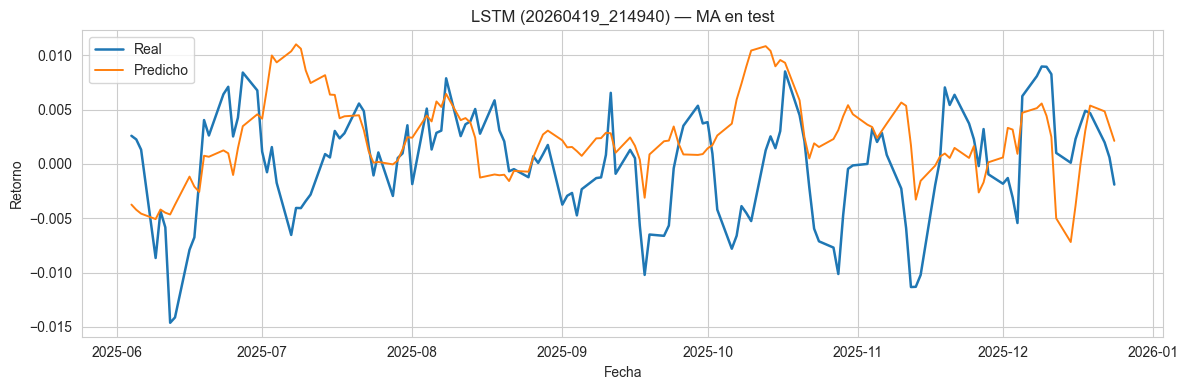

In [99]:
# Gráfico real vs predicho para un ticker ejemplo de la corrida definitiva
TICKER_EXAMPLE = 'MA'
pred_file = LSTM_DIR / LSTM_FINAL_RUN_ID / 'per_ticker' / f'{TICKER_EXAMPLE}_predictions.csv'

if pred_file.exists():
    pred = pd.read_csv(pred_file, parse_dates=['date'])
    pred_test = pred[pred['split'] == 'test'].copy()

    plt.figure(figsize=(12, 4))
    plt.plot(pred_test['date'], pred_test['y_true'], label='Real', linewidth=1.8)
    plt.plot(pred_test['date'], pred_test['y_pred'], label='Predicho', linewidth=1.4)
    plt.title(f'LSTM ({LSTM_FINAL_RUN_ID}) — {TICKER_EXAMPLE} en test')
    plt.xlabel('Fecha')
    plt.ylabel('Retorno')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f'No existe archivo por ticker: {pred_file}')


In [ ]:
# Evaluación GJR-GARCH y chequeo de fallback EWMA
vol_pred = pd.read_csv(ROOT / 'outputs' / 'predictions' / 'volatility_predictions.csv')

source_counts = vol_pred['model_source'].value_counts(dropna=False).rename_axis('model_source').reset_index(name='n_tickers')
source_counts['pct'] = source_counts['n_tickers'] / len(vol_pred)

ewma_fallback_mask = vol_pred['model_source'].astype(str).str.contains('ewma', case=False, na=False)

garch_summary = pd.DataFrame([{
    'n_tickers_total': int(len(vol_pred)),
    'n_gjr_garch': int((vol_pred['model_source'] == 'gjr_garch_t').sum()),
    'n_fallback_ewma': int(ewma_fallback_mask.sum()),
    'vol_pred_min': float(vol_pred['vol_pred'].min()),
    'vol_pred_max': float(vol_pred['vol_pred'].max()),
    'vol_pred_mean': float(vol_pred['vol_pred'].mean()),
}])

print('Fuentes de modelo para volatilidad:')
display(source_counts)

print('\nResumen GJR-GARCH / fallback:')
display(garch_summary)

if ewma_fallback_mask.sum() == 0:
    print('Conclusión: no hubo fallback a EWMA en esta corrida de volatilidad (todas las series salieron con gjr_garch_t).')


Fuentes de modelo para volatilidad:


,model_source,n_tickers,pct
0,gjr_garch_t,40,1.0



Resumen GJR-GARCH / fallback:


,n_tickers_total,n_gjr_garch,n_fallback_ewma,vol_pred_min,vol_pred_max,vol_pred_mean
0,40,40,0,0.001792,0.040676,0.019085


Conclusión: no hubo fallback a EWMA en esta corrida de volatilidad (todas las series salieron con gjr_garch_t).


## 4.3 Impacto en la optimización de portafolios (Classic vs LSTM vs GRJ GARCH)

In [ ]:
# Cargar corridas de optimización (run IDs 24,25,26) desde SQLite
assert DB_PATH.exists(), f'No existe DB local: {DB_PATH}'

con = sqlite3.connect(DB_PATH)
run_ids = ','.join(str(v['run_id']) for v in OPTIMIZATION_RUNS.values())
query = f'''SELECT id, created_at, model_type, max_weight, rf_annual_simple, n_frontier_points,
                   targets_json, metrics_json, comparison_json, block_exposure_json, weights_json, frontier_json
            FROM optimization_runs
            WHERE id IN ({run_ids})
            ORDER BY id'''
opt_raw = pd.read_sql_query(query, con)
con.close()

id_to_label = {v['run_id']: k for k, v in OPTIMIZATION_RUNS.items()}
id_to_mlflow = {v['run_id']: v['mlflow_run_id'] for v in OPTIMIZATION_RUNS.values()}
opt_raw['escenario'] = opt_raw['id'].map(id_to_label)
opt_raw['mlflow_run_id'] = opt_raw['id'].map(id_to_mlflow)

display(opt_raw[['id', 'escenario', 'mlflow_run_id', 'model_type', 'max_weight', 'rf_annual_simple', 'n_frontier_points']])


In [ ]:
# Tabla comparativa de métricas de portfolio 'Max Sharpe + Blocks'
rows = []
for _, r in opt_raw.iterrows():
    comparison = json.loads(r['comparison_json']) if r['comparison_json'] else []
    blocks = next((x for x in comparison if str(x.get('portfolio', '')).lower().strip() == 'max sharpe + blocks'), None)
    if blocks is None and len(comparison) > 0:
        blocks = comparison[-1]

    rows.append({
        'escenario': r['escenario'],
        'run_id_db': int(r['id']),
        'mlflow_run_id': r['mlflow_run_id'],
        'model_type': r['model_type'],
        'return_annual_blocks': blocks.get('return_annual') if blocks else np.nan,
        'vol_annual_blocks': blocks.get('vol_annual') if blocks else np.nan,
        'sharpe_annual_blocks': blocks.get('sharpe_annual') if blocks else np.nan,
    })

opt_blocks_metrics = pd.DataFrame(rows).sort_values('sharpe_annual_blocks', ascending=False)
display(opt_blocks_metrics)


In [ ]:
# Verificación de mismas ponderaciones objetivo por bloque
targets_rows = []
for _, r in opt_raw.iterrows():
    targets = json.loads(r['targets_json']) if r['targets_json'] else {}
    targets_rows.append({'escenario': r['escenario'], **targets})

targets_df = pd.DataFrame(targets_rows)

print('Targets declarados por corrida:')
display(targets_df)
print('Targets de referencia esperados:')
display(pd.DataFrame([{'escenario': 'REFERENCIA', **TARGET_BLOCKS}]))


In [ ]:
# Tabla de pesos (top) para copiar al capítulo 4.3
weights_tables = {}
for _, r in opt_raw.iterrows():
    w = pd.DataFrame(json.loads(r['weights_json']))
    w = w[['ticker', 'block', 'weight']].sort_values('weight', ascending=False).reset_index(drop=True)
    weights_tables[r['escenario']] = w

for scenario, wdf in weights_tables.items():
    print(f'\nTop 15 pesos - {scenario}')
    display(wdf.head(15))


In [ ]:
# Comparación de fronteras eficientes
plt.figure(figsize=(8, 6))
for _, r in opt_raw.iterrows():
    frontier = pd.DataFrame(json.loads(r['frontier_json']))
    plt.plot(frontier['vol_annual'], frontier['return_annual'], label=f"{r['escenario']} (run {int(r['id'])})")

plt.title('Comparación de fronteras eficientes')
plt.xlabel('Volatilidad anual')
plt.ylabel('Retorno anual')
plt.legend()
plt.tight_layout()
plt.show()


## 4.4 Discusión de resultados (plantilla guiada)

Usá lo que sale en las tablas anteriores para redactar esta parte:

1. **Modelos predictivos:**
   - Cómo evolucionó el historial de corridas LSTM.
   - Justificación de la corrida definitiva (`20260419_214940`) y sus hiperparámetros.
   - Cuántos activos pasaron el umbral `dir_acc_test > 0.52` y cuántos quedaron con fallback histórico.

2. **Volatilidad (GJR-GARCH):**
   - Confirmar si hubo fallback a EWMA.
   - Si no hubo fallback, explicar que todas las series convergieron bajo `gjr_garch_t`.

3. **Optimización de portafolios:**
   - Comparar rendimiento/riesgo/sharpe de Classic vs LSTM vs GRJ GARCH.
   - Analizar diferencias de pesos y exposición por bloque con targets fijos.

4. **Conclusión práctica:**
   - Qué input (histórico vs IA retornos LSTM vs IA volatilidad GJR) aporta mayor valor en tu configuración de bloques.
